**Phase 2 - Cross-sensitivity and mutli-gas recover evaluation**

**Question:** Given hour, weather, adn all five low-cost sensors, how well can the network recover each reference gas, and does the cross-sensitivity structure help?

This notebook evaluates the Phase 2 graph selected in notebooks/phase2/cross-sensitivity.ipynb:
* Nominal-only: S1 $\leftarrow$ CO, S3 $\leftarrow$ NOx, S4 $\leftarrow$ NO2
* Nominal + cross: additionally S2 $\leftarrow$ C6H6 (structural proxy edge), S4 $\leftarrow$ CO + NOx, and S5 $\leftarrow$ CO + NOx
* Every modeled gas has hour as its parent; every sensor also has weather T and AH as parents.
* NMHC is excluded from the primary network because roughly 90% of its reference readings are missing. Its sparsity is quantified below; it is not silently treated as a fifth well-observed gas.

**Evaluation Rules**

1. The discretizer is fitted on training rows only, using the four modeled gases, five sensors, and weather.
2. Each network is fitted once per (edge set, bins, seed) and resused for all four gas queries.
3. Prediction evidence is always (hour, T, AH, S1, ... , S5). No gas reference is evidence.
4. Validation selects the edge set and bin count using concentration error relative to resolution floor. Test is evaluated once, after selection.
5. The drop-one-sensor ablation masks a senosr at prediction time while retaining the same fitted network, isolating how much that sensor contributes to inference.

**Model assumptions to assess**
* A1: gases are independent given hour
* A2: sensors are independent given their gas parents and weather.
* A3: missingness is ignorable given observed values (MAR)
* A4: hours are independent given the CPTs: temporal dependence is left to Phase 4

**1. Setup and configuration**

In [ ]:
%load_ext autoreload
%autoreload 2

import json
import math
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cse250a.modules.eval.correlation import partial_spearman
from tqdm.auto import tqdm

from cse250a.modules.config import config
from cse250a.modules.core import TIME_CARDS, Gas, Network, Sensor, Time, Weather
from cse250a.modules.data import Discretizer, blocked_split, load_air_quality
from cse250a.modules.eval.concentration import (
    bin_means,
    concentration_error,
    expected_concentration,
    resolution_floor,
)
from cse250a.modules.models import DiscreteBN, HourOnlyBaseline

SEEDS = (0, 1, 2)
BIN_COUNTS = (3, 5)
GASES = (Gas.CO, Gas.C6H6, Gas.NOX, Gas.NO2)
SENSORS = tuple(Sensor)
WEATHER = (Weather.T, Weather.AH)
EVIDENCE = (Time.HOUR, *WEATHER, *SENSORS)
ALPHA = 1.0
EM_MAX_ITER = 100
FIG_DIR = Path('figures/phase2')
RESULT_DIR = Path('results/phase2')
GRID_PATH = Path('notebooks/experiments/phase2_eval_grid.png')
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False})

# Final graph decision from docs/decisions.md and the cross-sensitivity study.
NOMINAL = {
    Sensor.S1: (Gas.CO,),
    Sensor.S3: (Gas.NOX,),
    Sensor.S4: (Gas.NO2,),
}
CROSS = {
    Sensor.S2: (Gas.C6H6,),  # structural proxy edge: C6H6 reference is effectively S2-derived
    Sensor.S4: (Gas.CO, Gas.NOX),
    Sensor.S5: (Gas.CO, Gas.NOX),
}

print('Repository root:', config.paths.air_quality_csv.parent.parent.parent)
print('Gases:', [str(g) for g in GASES])
print('Sensors:', [str(s) for s in SENSORS])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Repository root: /workspaces/CSE-250A-Project
Gases: ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']
Sensors: ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)']


**2. Load data and inspect missingness**

Hour and weather are input variables without CPTs, so rows missing any of them cannot be used by this static networ and are removed. Missing gas references and missing sensor readings are retained; the BN can marginalized them during EM and inference.

In [6]:
raw_all = load_air_quality(config.paths.air_quality_csv)
missingness = raw_all[[*GASES, Gas.NMHC, *SENSORS, *WEATHER]].isna().mean().rename('missing_fraction')
missingness.to_frame()

,missing_fraction
CO(GT),0.179865
C6H6(GT),0.039115
NOx(GT),0.175163
NO2(GT),0.175484
NMHC(GT),0.902319
PT08.S1(CO),0.039115
PT08.S2(NMHC),0.039115
PT08.S3(NOx),0.039115
PT08.S4(NO2),0.039115
PT08.S5(O3),0.039115


In [9]:
before = len(raw_all)
raw = raw_all.dropna(subset=[Time.HOUR, *WEATHER]).copy()
print(f'Rows retained: {len(raw):,}/{before:,}; removed {before-len(raw):,} with missing hour/weather.')
print('Date range:', raw.index.min(), 'to', raw.index.max())
print('\nReference missingness after required-input filtering:')
display(raw[[*GASES, Gas.NMHC]].isna().mean().rename('missing_fraction').to_frame())

Rows retained: 8,991/9,357; removed 366 with missing hour/weather.
Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00

Reference missingness after required-input filtering:


,missing_fraction
CO(GT),0.183183
C6H6(GT),0.000000
NOx(GT),0.177400
NO2(GT),0.177733
NMHC(GT),0.901346


**3. Build the two network structures**

The nominal-only graph leaves S2 and S5 without gas parents because their nominal references (NMHC and O3) are not usable in this dataset. They still have weather parents. The cross graph adds the selected study edges. The gas nodes themselves remain independent roots conditional on hour in both structures.

In [10]:
def make_network(cards, include_cross: bool):
    structure = {gas: (Time.HOUR,) for gas in GASES}
    sensor_parents = {}
    for sensor in SENSORS:
        parents = list(NOMINAL.get(sensor, ()))
        if include_cross:
            parents.extend(CROSS.get(sensor, ()))
        # Preserve order and avoid accidental duplicate parents.
        parents = list(dict.fromkeys(parents))
        sensor_parents[sensor] = tuple(parents)
        structure[sensor] = (*parents, *WEATHER)
    return Network(structure=structure, cards=cards).validate(), sensor_parents

# Preview structures and CPT sizes at 3 bins.
_preview_cards = {**{str(c): 3 for c in [*GASES, *SENSORS, *WEATHER]}, **TIME_CARDS}
for label, include_cross in [('nominal-only', False), ('nominal+cross', True)]:
    net, _ = make_network(_preview_cards, include_cross)
    print(f'\n{label}:')
    print(net)


nominal-only:
Network(9 nodes, inputs: hour, T, AH)
          CO(GT) | hour                          CPT shape (24, 3)
        C6H6(GT) | hour                          CPT shape (24, 3)
         NOx(GT) | hour                          CPT shape (24, 3)
         NO2(GT) | hour                          CPT shape (24, 3)
     PT08.S1(CO) | CO(GT), T, AH                 CPT shape (3, 3, 3, 3)
   PT08.S2(NMHC) | T, AH                         CPT shape (3, 3, 3)
    PT08.S3(NOx) | NOx(GT), T, AH                CPT shape (3, 3, 3, 3)
    PT08.S4(NO2) | NO2(GT), T, AH                CPT shape (3, 3, 3, 3)
     PT08.S5(O3) | T, AH                         CPT shape (3, 3, 3)

nominal+cross:
Network(9 nodes, inputs: hour, T, AH)
          CO(GT) | hour                          CPT shape (24, 3)
        C6H6(GT) | hour                          CPT shape (24, 3)
         NOx(GT) | hour                          CPT shape (24, 3)
         NO2(GT) | hour                          CPT shape (24, 3)
   

**4. Metric Helpers**

For each gas we report accuracy, within-one-bin accuracy, macro-F1, mean log-likelihood of the true bin, concentration MAE/RMSE, and top-label calibration error (ECE). Gains are paired differences against HourOnlyBaseline on the same validation split. For concentration error, positive gain means the BN has lower error.

In [11]:
def classification_metrics(y_binned: pd.Series, proba: pd.DataFrame):
    valid = y_binned.notna() & proba.notna().all(axis=1)
    y = y_binned.loc[valid].astype(int).to_numpy()
    p = proba.loc[valid].to_numpy(dtype=float)
    labels = np.asarray(proba.columns, dtype=int)
    pred = labels[p.argmax(axis=1)]
    confidence = p.max(axis=1)
    hit = (pred == y).astype(float)
    p_true = p[np.arange(len(y)), y]
    f1s = []
    for label in labels:
        tp = np.sum((pred == label) & (y == label))
        fp = np.sum((pred == label) & (y != label))
        fn = np.sum((pred != label) & (y == label))
        f1s.append(0.0 if 2*tp + fp + fn == 0 else 2*tp/(2*tp+fp+fn))
    # Top-label ECE: weighted |confidence - empirical accuracy| over equal-width bins.
    ece = 0.0
    for lo, hi in zip(np.linspace(0, 1, 11)[:-1], np.linspace(0, 1, 11)[1:]):
        mask = (confidence >= lo) & (confidence < hi if hi < 1 else confidence <= hi)
        if mask.any():
            ece += mask.mean() * abs(confidence[mask].mean() - hit[mask].mean())
    return {
        'n': int(len(y)),
        'accuracy': float(hit.mean()) if len(y) else np.nan,
        'within_one_bin': float((np.abs(pred-y) <= 1).mean()) if len(y) else np.nan,
        'macro_f1': float(np.mean(f1s)) if len(y) else np.nan,
        'mean_log_likelihood': float(np.log(np.clip(p_true, 1e-15, 1)).mean()) if len(y) else np.nan,
        'ECE': float(ece) if len(y) else np.nan,
        'confusion': pd.crosstab(pd.Series(y, name='true'), pd.Series(pred, name='pred')),
        'confidence': confidence,
        'hit': hit,
    }


def score_one_gas(proba, binned_truth, raw_truth, c_bar):
    cls = classification_metrics(binned_truth, proba)
    estimate = expected_concentration(proba, c_bar)
    conc = concentration_error(estimate, raw_truth)
    floor = resolution_floor(raw_truth, binned_truth, c_bar)
    metrics = {k: cls[k] for k in ('n', 'accuracy', 'within_one_bin', 'macro_f1', 'mean_log_likelihood', 'ECE')}
    metrics.update({f'conc_{k}': v for k, v in conc.items() if k != 'n'})
    metrics['floor_MAE'] = floor['MAE']
    metrics['floor_RMSE'] = floor['RMSE']
    return metrics, estimate, cls


def summarize_mean_std(frame, group_cols, metrics):
    agg = frame.groupby(group_cols)[metrics].agg(['mean', 'std']).reset_index()
    agg.columns = ['_'.join(str(x) for x in c if x) if isinstance(c, tuple) else c for c in agg.columns]
    return agg

**5. Validation grid: edge sets x bins x seeds**

For each of the 12 configurations, fit one BN and one hour-only baseline. Each model's posterior is computed exactly once per gas and cached. The complete-case fit (max_iter=1) is reserved for the focused EM comparison later; the main grid uses EM with up to 100 iterations.

The concentration selection score is the mean across gases of (BN MAE - resolution-floor MAE) / HourOnlyBaseline MAE. Lower is better: it measures the remaining gap above the discretization floor relative to the baseline's error. 

In [12]:
grid_rows = []
concentration_rows = []
validation_cache = {}
model_cache = {}

for edge_name, include_cross in [('nominal-only', False), ('nominal+cross', True)]:
    for n_bins in BIN_COUNTS:
        for seed in SEEDS:
            train_raw, val_raw, test_raw = blocked_split(raw, seed=seed)
            disc = Discretizer(n_bins=n_bins).fit(train_raw, [*GASES, *SENSORS, *WEATHER])
            train, val, test = (disc.transform(x) for x in (train_raw, val_raw, test_raw))
            cards = {**disc.cards, **TIME_CARDS}
            network, sensor_parents = make_network(cards, include_cross)

            bn = DiscreteBN(network, alpha=ALPHA, max_iter=EM_MAX_ITER, seed=seed).fit(train)
            hour = HourOnlyBaseline(cards=cards, alpha=ALPHA).fit(train)
            c_bars = {g: bin_means(train_raw[g], train[g]) for g in GASES}

            cache_key = (edge_name, n_bins, seed)
            model_cache[cache_key] = {
                'bn': bn, 'hour': hour, 'network': network, 'cards': cards,
                'disc': disc, 'train_raw': train_raw, 'val_raw': val_raw,
                'test_raw': test_raw, 'train': train, 'val': val, 'test': test,
                'c_bars': c_bars, 'sensor_parents': sensor_parents,
            }
            cache = {'BN': {}, 'HourOnlyBaseline': {}}
            for model_name, model in [('BN', bn), ('HourOnlyBaseline', hour)]:
                for gas in GASES:
                    # The same evidence is used for every gas; reference gases are masked by Model.
                    proba = model.predict_proba(val, gas, EVIDENCE)
                    metrics, estimate, cls = score_one_gas(proba, val[gas], val_raw[gas], c_bars[gas])
                    cache[model_name][gas] = {'proba': proba, 'estimate': estimate, 'metrics': metrics, 'classification': cls}
                    concentration_rows.append({
                        'edges': edge_name, 'bins': n_bins, 'seed': seed,
                        'gas': str(gas), 'model': model_name,
                        'n': metrics['n'], 'MAE': metrics['conc_MAE'], 'RMSE': metrics['conc_RMSE'],
                        'floor_MAE': metrics['floor_MAE'], 'floor_RMSE': metrics['floor_RMSE'],
                    })
                    grid_rows.append({
                        'edges': edge_name, 'bins': n_bins, 'seed': seed,
                        'gas': str(gas), 'model': model_name, **metrics,
                    })
            validation_cache[cache_key] = cache
            print(f'Finished {cache_key}; EM iterations={bn.result.n_iter}, converged={bn.result.converged}')

metrics_grid = pd.DataFrame(grid_rows)
concentration_grid = pd.DataFrame(concentration_rows)
metrics_grid.drop(columns=[], errors='ignore').to_csv(RESULT_DIR / 'phase2_validation_metrics_by_seed.csv', index=False)
concentration_grid.to_csv(RESULT_DIR / 'phase2_validation_concentration_by_seed.csv', index=False)

Finished ('nominal-only', 3, 0); EM iterations=5, converged=True
Finished ('nominal-only', 3, 1); EM iterations=5, converged=True
Finished ('nominal-only', 3, 2); EM iterations=6, converged=True
Finished ('nominal-only', 5, 0); EM iterations=8, converged=True
Finished ('nominal-only', 5, 1); EM iterations=6, converged=True
Finished ('nominal-only', 5, 2); EM iterations=6, converged=True
Finished ('nominal+cross', 3, 0); EM iterations=5, converged=True
Finished ('nominal+cross', 3, 1); EM iterations=4, converged=True
Finished ('nominal+cross', 3, 2); EM iterations=4, converged=True
Finished ('nominal+cross', 5, 0); EM iterations=6, converged=True
Finished ('nominal+cross', 5, 1); EM iterations=5, converged=True
Finished ('nominal+cross', 5, 2); EM iterations=4, converged=True


**6. Per-gas results and gains over HourOnlyBaseline**

In [13]:
METRICS = ['accuracy', 'within_one_bin', 'macro_f1', 'mean_log_likelihood', 'ECE']
metric_summary = (metrics_grid.groupby(['edges', 'bins', 'gas', 'model'])
                  .agg(n_mean=('n', 'mean'), **{f'{m}_mean': (m, 'mean') for m in METRICS},
                       **{f'{m}_std': (m, 'std') for m in METRICS})
                  .reset_index())
metric_summary.round(4)

,edges,bins,gas,model,n_mean,accuracy_mean,within_one_bin_mean,macro_f1_mean,mean_log_likelihood_mean,ECE_mean,accuracy_std,within_one_bin_std,macro_f1_std,mean_log_likelihood_std,ECE_std
0,nominal+cross,3,C6H6(GT),BN,2189.6667,0.9982,1.0000,0.9982,-0.0210,0.0115,0.0012,0.0000,0.0012,0.0073,0.0015
1,nominal+cross,3,C6H6(GT),HourOnlyBaseline,2189.6667,0.5439,0.8984,0.5369,-0.8882,0.0449,0.0151,0.0288,0.0221,0.0138,0.0069
2,nominal+cross,3,CO(GT),BN,1853.0000,0.7724,0.9922,0.7693,-0.5699,0.0747,0.0129,0.0040,0.0174,0.0408,0.0072
3,nominal+cross,3,CO(GT),HourOnlyBaseline,1853.0000,0.5857,0.9373,0.5891,-0.8994,0.0468,0.0242,0.0178,0.0243,0.0485,0.0125
4,nominal+cross,3,NO2(GT),BN,1854.6667,0.5525,0.9157,0.5383,-0.9310,0.0424,0.0287,0.0200,0.0199,0.0176,0.0126
5,nominal+cross,3,NO2(GT),HourOnlyBaseline,1854.6667,0.5355,0.8890,0.5006,-0.9648,0.0728,0.0386,0.0441,0.0247,0.0103,0.0148
6,nominal+cross,3,NOx(GT),BN,1855.0000,0.7079,0.9821,0.6837,-0.6316,0.0614,0.0171,0.0098,0.0237,0.0238,0.0153
7,nominal+cross,3,NOx(GT),HourOnlyBaseline,1855.0000,0.4946,0.9044,0.4843,-1.0000,0.0606,0.0407,0.0471,0.0360,0.0160,0.0371
8,nominal+cross,5,C6H6(GT),BN,2189.6667,0.9883,0.9957,0.9880,-0.1282,0.0773,0.0021,0.0020,0.0021,0.0085,0.0008
9,nominal+cross,5,C6H6(GT),HourOnlyBaseline,2189.6667,0.4086,0.7358,0.3785,-1.3623,0.0303,0.0113,0.0210,0.0055,0.0222,0.0066


In [14]:
# Paired BN-minus-baseline gains; for ECE, negative is an improvement.
wide = metrics_grid.pivot(index=['edges', 'bins', 'seed', 'gas'], columns='model', values=METRICS)
gain_rows = []
for idx, row in wide.iterrows():
    rec = dict(zip(['edges', 'bins', 'seed', 'gas'], idx))
    for metric in METRICS:
        rec[f'{metric}_gain_BN_minus_hour'] = row[(metric, 'BN')] - row[(metric, 'HourOnlyBaseline')]
    gain_rows.append(rec)
gain_grid = pd.DataFrame(gain_rows)
gain_summary = gain_grid.groupby(['edges', 'bins', 'gas']).agg(['mean', 'std']).round(4)
gain_summary

seed      accuracy_gain_BN_minus_hour          \
                            mean  std                        mean     std   
edges         bins gas                                                      
nominal+cross 3    C6H6(GT)  1.0  1.0                      0.4542  0.0159   
                   CO(GT)    1.0  1.0                      0.1867  0.0114   
                   NO2(GT)   1.0  1.0                      0.0170  0.0169   
                   NOx(GT)   1.0  1.0                      0.2133  0.0540   
              5    C6H6(GT)  1.0  1.0                      0.5797  0.0115   
                   CO(GT)    1.0  1.0                      0.1990  0.0186   
                   NO2(GT)   1.0  1.0                      0.0223  0.0119   
                   NOx(GT)   1.0  1.0                      0.2764  0.0285   
nominal-only  3    C6H6(GT)  1.0  1.0                      0.0000  0.0000   
                   CO(GT)    1.0  1.0                      0.1588  0.0060   
                   NO2(GT)   1.0  1.0                      0.0025  0.0256   
                   NOx(GT)   1.0  1.0                      0.1724  0.0401   
              5    C6H6(GT)  1.0  1.0                      0.0000  0.0000   
                   CO(GT)    1.0  1.0                      0.1632  0.0283   
                   NO2(GT)   1.0  1.0                      0.0247  0.0187   
                   NOx(GT)   1.0  1.0                      0.2131  0.0302   

                            within_one_bin_gain_BN_minus_hour          \
                                                         mean     std   
edges         bins gas                                                  
nominal+cross 3    C6H6(GT)                            0.1016  0.0288   
                   CO(GT)                              0.0550  0.0189   
                   NO2(GT)                             0.0267  0.0241   
                   NOx(GT)                             0.0777  0.0380   
              5    C6H6(GT)                            0.2599  0.0203   
                   CO(GT)                              0.1905  0.0358   
                   NO2(GT)                             0.0277  0.0208   
                   NOx(GT)                             0.2843  0.0154   
nominal-only  3    C6H6(GT)                            0.0000  0.0000   
                   CO(GT)                              0.0528  0.0156   
                   NO2(GT)                             0.0287  0.0372   
                   NOx(GT)                             0.0684  0.0396   
              5    C6H6(GT)                            0.0000  0.0000   
                   CO(GT)                              0.1783  0.0376   
                   NO2(GT)                             0.0242  0.0211   
                   NOx(GT)                             0.2541  0.0266   

                            macro_f1_gain_BN_minus_hour          \
                                                   mean     std   
edges         bins gas                                            
nominal+cross 3    C6H6(GT)                      0.4612  0.0226   
                   CO(GT)                        0.1802  0.0107   
                   NO2(GT)                       0.0377  0.0182   
                   NOx(GT)                       0.1994  0.0592   
              5    C6H6(GT)                      0.6095  0.0069   
                   CO(GT)                        0.2172  0.0216   
                   NO2(GT)                       0.0340  0.0046   
                   NOx(GT)                       0.3011  0.0227   
nominal-only  3    C6H6(GT)                      0.0000  0.0000   
                   CO(GT)                        0.1538  0.0036   
                   NO2(GT)                       0.0261  0.0092   
                   NOx(GT)                       0.1573  0.0442   
              5    C6H6(GT)                      0.0000  0.0000   
                   CO(GT)                        0.1816  0.0300   
                   NO2(GT)           

**7. Concentration error and resolution floor**

The concentration estimate is the posterior-weighted training-bin mean. $\sum_{j} P(\text{bin} = j \mid \text{evidence}) \cdot \bar{c}_j$. The resolution floor uses the true validation bin and the same training-bin means, so it isolates error caused by discretization itself.

In [15]:
conc_summary = (concentration_grid.groupby(['edges', 'bins', 'gas', 'model'])
                .agg(n_mean=('n', 'mean'), MAE_mean=('MAE', 'mean'), MAE_std=('MAE', 'std'),
                     RMSE_mean=('RMSE', 'mean'), RMSE_std=('RMSE', 'std'),
                     floor_MAE_mean=('floor_MAE', 'mean'), floor_RMSE_mean=('floor_RMSE', 'mean'))
                .reset_index())
for metric in ['MAE', 'RMSE']:
    conc_summary[f'{metric} mean ± std'] = conc_summary.apply(
        lambda r: f"{r[f'{metric}_mean']:.4f} ± {r[f'{metric}_std']:.4f}" if pd.notna(r[f'{metric}_std']) else f"{r[f'{metric}_mean']:.4f} ± n/a", axis=1)
conc_summary[['edges', 'bins', 'gas', 'model', 'n_mean', 'MAE mean ± std', 'RMSE mean ± std', 'floor_MAE_mean']]

,edges,bins,gas,model,n_mean,MAE mean ± std,RMSE mean ± std,floor_MAE_mean
0,nominal+cross,3,C6H6(GT),BN,2189.666667,2.3598 ± 0.1194,3.7158 ± 0.3125,2.389238
1,nominal+cross,3,C6H6(GT),HourOnlyBaseline,2189.666667,4.5265 ± 0.2171,6.1014 ± 0.3089,2.389238
2,nominal+cross,3,CO(GT),BN,1853.000000,0.5436 ± 0.0391,0.8068 ± 0.0662,0.460769
3,nominal+cross,3,CO(GT),HourOnlyBaseline,1853.000000,0.8570 ± 0.0391,1.1511 ± 0.0356,0.460769
4,nominal+cross,3,NO2(GT),BN,1854.666667,31.0509 ± 2.6255,40.4246 ± 3.8355,16.980591
5,nominal+cross,3,NO2(GT),HourOnlyBaseline,1854.666667,31.9767 ± 2.8023,41.4433 ± 3.9894,16.980591
6,nominal+cross,3,NOx(GT),BN,1855.000000,89.5126 ± 1.3748,132.7053 ± 11.2223,74.131185
7,nominal+cross,3,NOx(GT),HourOnlyBaseline,1855.000000,136.4695 ± 5.5857,186.4560 ± 19.5856,74.131185
8,nominal+cross,5,C6H6(GT),BN,2189.666667,1.7482 ± 0.1212,2.9579 ± 0.2641,1.610455
9,nominal+cross,5,C6H6(GT),HourOnlyBaseline,2189.666667,4.4809 ± 0.2123,6.0486 ± 0.2953,1.610455


**Nominal-only versus nominal + cross edges**

Compare paired validation scores by bin count and gas. A positive likelihood/accuracy gain favors the cross graph; a negative ECE gain favors it because lower ECE is better. Concentration MAE/RMSE differences are reported in the original units of each gas.

In [16]:
edge_compare = metrics_grid[metrics_grid.model == 'BN'].pivot_table(
    index=['bins', 'seed', 'gas'], columns='edges', values=METRICS + ['conc_MAE', 'conc_RMSE'])
edge_delta_rows=[]
for idx, row in edge_compare.iterrows():
    bins, seed, gas = idx
    rec={'bins':bins, 'seed':seed, 'gas':gas}
    for metric in METRICS + ['conc_MAE', 'conc_RMSE']:
        rec[f'{metric}_cross_minus_nominal'] = row[(metric, 'nominal+cross')] - row[(metric, 'nominal-only')]
    edge_delta_rows.append(rec)
edge_deltas = pd.DataFrame(edge_delta_rows)
edge_delta_summary = edge_deltas.groupby(['bins','gas']).agg(['mean','std']).round(4)
edge_delta_summary

seed      accuracy_cross_minus_nominal          \
              mean  std                         mean     std   
bins gas                                                       
3    C6H6(GT)  1.0  1.0                       0.4542  0.0159   
     CO(GT)    1.0  1.0                       0.0279  0.0103   
     NO2(GT)   1.0  1.0                       0.0145  0.0252   
     NOx(GT)   1.0  1.0                       0.0409  0.0140   
5    C6H6(GT)  1.0  1.0                       0.5797  0.0115   
     CO(GT)    1.0  1.0                       0.0358  0.0100   
     NO2(GT)   1.0  1.0                      -0.0024  0.0085   
     NOx(GT)   1.0  1.0                       0.0633  0.0117   

              within_one_bin_cross_minus_nominal          \
                                            mean     std   
bins gas                                                   
3    C6H6(GT)                             0.1016  0.0288   
     CO(GT)                               0.0021  0.0038   
     NO2(GT)                             -0.0020  0.0137   
     NOx(GT)                              0.0093  0.0056   
5    C6H6(GT)                             0.2599  0.0203   
     CO(GT)                               0.0122  0.0060   
     NO2(GT)                              0.0035  0.0096   
     NOx(GT)                              0.0303  0.0120   

              macro_f1_cross_minus_nominal          \
                                      mean     std   
bins gas                                             
3    C6H6(GT)                       0.4612  0.0226   
     CO(GT)                         0.0264  0.0076   
     NO2(GT)                        0.0116  0.0161   
     NOx(GT)                        0.0421  0.0168   
5    C6H6(GT)                       0.6095  0.0069   
     CO(GT)                         0.0356  0.0083   
     NO2(GT)                       -0.0022  0.0069   
     NOx(GT)                        0.0658  0.0077   

              mean_log_likelihood_cross_minus_nominal          \
                                                 mean     std   
bins gas                                                        
3    C6H6(GT)                                  0.8672  0.0208   
     CO(GT)                                    0.0276  0.0230   
     NO2(GT)                                   0.0427  0.0238   
     NOx(GT)                                   0.0545  0.0243   
5    C6H6(GT)                                  1.2342  0.0295   
     CO(GT)                                    0.0441  0.0269   
     NO2(GT)                                   0.0576  0.0353   
     NOx(GT)                                   0.0971  0.0244   

              ECE_cross_minus_nominal         conc_MAE_cross_minus_nominal  \
                                 mean     std                         mean   
bins gas                                                                     
3    C6H6(GT)                 -0.0335  0.0079                      -2.1668   
     CO(GT)                    0.0456  0.0129                      -0.0460   
     NO2(GT)                  -0.0438  0.0162                      -0.9378   
     NOx(GT)                   0.0158  0.0057                      -5.8055   
5    C6H6(GT)                  0.0473  0.0064                      -2.7327   
     CO(GT)                    0.0529  0.0108                      -0.0475   
     NO2(GT)                  -0.0376  0.0029                      -1.1262   
     NOx(GT)                   0.0144  0.0168                      -9.5149   

                      conc_RMSE_cross_minus_nominal          
                  std                          mean     std  
bins gas                                                     
3    C6H6(GT)  0.1720                       -2.3855  0.1550  
     CO(GT)    0.0186                       -0.0532  0.0170  
     NO2(GT)   0.8126                       -0.6321  1.1851  
     NOx(GT)   3.1316                       -5.3443  1.2960  
5    C6H6(GT)  0.1222                       

In [17]:
# Compact across-gas view. Concentration gains are scaled by the hour baseline MAE
# so gases with different units do not dominate the selection score.
selection_rows=[]
for (edges, bins, seed), sub in concentration_grid[concentration_grid.model == 'BN'].groupby(['edges','bins','seed']):
    b = concentration_grid[(concentration_grid.edges==edges)&(concentration_grid.bins==bins)&
                           (concentration_grid.seed==seed)&(concentration_grid.model=='HourOnlyBaseline')].set_index('gas')
    s = sub.set_index('gas')
    floor_gap = ((s.MAE - s.floor_MAE) / b.MAE).replace([np.inf,-np.inf], np.nan)
    bn_vs_hour = ((b.MAE - s.MAE) / b.MAE).replace([np.inf,-np.inf], np.nan)
    selection_rows.append({'edges':edges,'bins':bins,'seed':seed,
                           'mean_normalized_gap_above_floor':floor_gap.mean(),
                           'mean_relative_MAE_gain_vs_hour':bn_vs_hour.mean()})
selection_grid = pd.DataFrame(selection_rows)
selection_summary = selection_grid.groupby(['edges','bins']).agg(['mean','std']).round(4)
selection_summary

seed      mean_normalized_gap_above_floor          \
                   mean  std                            mean     std   
edges         bins                                                     
nominal+cross 3     1.0  1.0                          0.1606  0.0478   
              5     1.0  1.0                          0.2459  0.0471   
nominal-only  3     1.0  1.0                          0.3116  0.0548   
              5     1.0  1.0                          0.4387  0.0564   

                   mean_relative_MAE_gain_vs_hour          
                                             mean     std  
edges         bins                                         
nominal+cross 3                            0.3038  0.0256  
              5                            0.3875  0.0127  
nominal-only  3                            0.1528  0.0174  
              5                            0.1947  0.0034

**9. Select the validation configuration**

Selection uses only validation concentration error. The primary source is the mean normalized gap above the resolution floor; the secondary column is mean relative MAE improvement over the hour baseline. The chosen edge/bin setting is the lowest mean, floor-gap score, with baseline improvement used as a tie-breaker.

In [18]:
selectable = selection_summary.copy()
# Flatten the groupby aggregation columns for stable indexing.
score_mean = selection_grid.groupby(['edges','bins'])['mean_normalized_gap_above_floor'].mean()
gain_mean = selection_grid.groupby(['edges','bins'])['mean_relative_MAE_gain_vs_hour'].mean()
selection_table = pd.DataFrame({'floor_gap_mean':score_mean, 'relative_MAE_gain_mean':gain_mean}).reset_index()
best = selection_table.sort_values(['floor_gap_mean','relative_MAE_gain_mean'], ascending=[True,False]).iloc[0]
CHOSEN_EDGES = str(best.edges)
CHOSEN_BINS = int(best.bins)
seed_scores = selection_grid[(selection_grid.edges==CHOSEN_EDGES)&(selection_grid.bins==CHOSEN_BINS)]
CHOSEN_SEED = int(seed_scores.iloc[(seed_scores.mean_normalized_gap_above_floor - best.floor_gap_mean).abs().argmin()].seed)
print('Chosen:', CHOSEN_EDGES, 'bins=', CHOSEN_BINS, 'representative seed=', CHOSEN_SEED)
display(selection_table.sort_values('floor_gap_mean'))

Chosen: nominal+cross bins= 3 representative seed= 1


,edges,bins,floor_gap_mean,relative_MAE_gain_mean
0,nominal+cross,3,0.160604,0.303798
1,nominal+cross,5,0.245912,0.387485
2,nominal-only,3,0.311640,0.152763
3,nominal-only,5,0.438660,0.194737


**10. Calibration and confusion matrices**

The reliability plot groups prediction by maximum posterior confidence and compares mean confidence with empirical top-bin accuracy. ECE summarizes the absolute gap. Confusion matrices are generated for the selected validation configuration; lower/upper-bin confusions are especially useful when bin ordering has physical meaning.

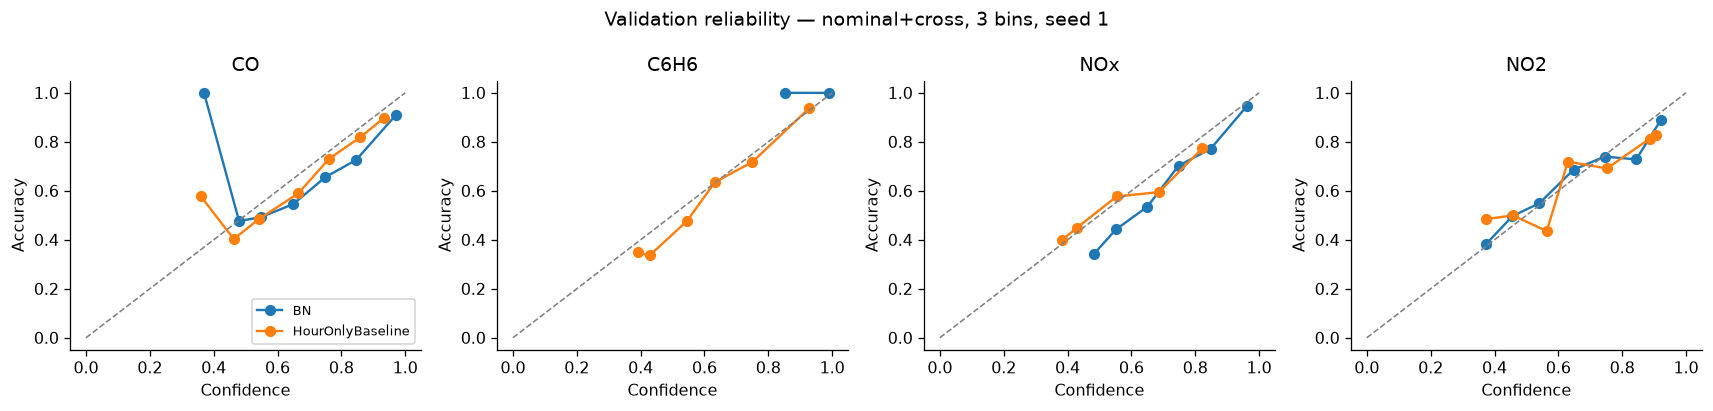

In [19]:
chosen_key = (CHOSEN_EDGES, CHOSEN_BINS, CHOSEN_SEED)
chosen_models = model_cache[chosen_key]
chosen_preds = validation_cache[chosen_key]

fig, axes = plt.subplots(1, len(GASES), figsize=(15, 3.6))
for ax, gas in zip(axes, GASES):
    for model_name, color in [('BN', 'tab:blue'), ('HourOnlyBaseline', 'tab:orange')]:
        d = chosen_preds[model_name][gas]['classification']
        conf, hit = d['confidence'], d['hit']
        bins = np.linspace(0,1,11)
        xs=[]; ys=[]
        for lo,hi in zip(bins[:-1],bins[1:]):
            m=(conf>=lo)&((conf<hi) if hi<1 else (conf<=hi))
            if m.any(): xs.append(conf[m].mean()); ys.append(hit[m].mean())
        ax.plot(xs,ys,marker='o',label=model_name,color=color)
    ax.plot([0,1],[0,1],ls='--',color='gray',lw=1)
    ax.set_title(str(gas).split('(')[0]); ax.set_xlabel('Confidence'); ax.set_ylabel('Accuracy')
axes[0].legend(fontsize=8)
fig.suptitle(f'Validation reliability — {CHOSEN_EDGES}, {CHOSEN_BINS} bins, seed {CHOSEN_SEED}')
fig.tight_layout()
fig.savefig(FIG_DIR/'reliability_selected.png',bbox_inches='tight')
plt.show()

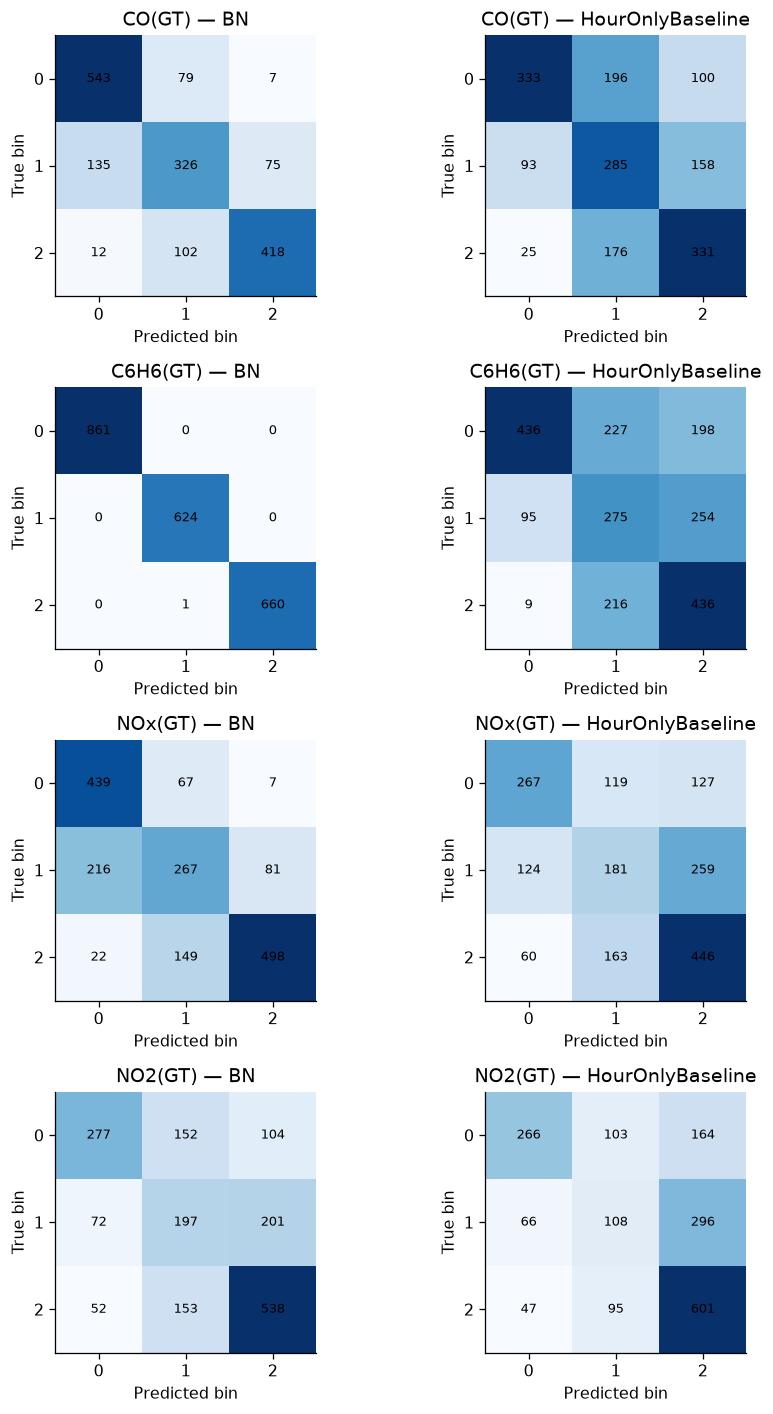

In [20]:
confusion_tables = []
fig, axes = plt.subplots(len(GASES), 2, figsize=(8, 3.1*len(GASES)))
for i, gas in enumerate(GASES):
    for j, model_name in enumerate(['BN','HourOnlyBaseline']):
        proba = chosen_preds[model_name][gas]['proba']
        truth = chosen_models['val'][gas]
        valid = truth.notna()
        pred = proba.loc[valid].idxmax(axis=1).astype(int)
        cm = pd.crosstab(truth.loc[valid].astype(int), pred, rownames=['true'], colnames=['pred'])
        cm.to_csv(RESULT_DIR/f'confusion_{str(gas).split("(")[0]}_{model_name}.csv')
        confusion_tables.append({'gas':str(gas),'model':model_name,'confusion':cm.to_dict()})
        ax=axes[i,j]
        im=ax.imshow(cm.to_numpy(),cmap='Blues')
        ax.set_title(f'{gas} — {model_name}')
        ax.set_xlabel('Predicted bin'); ax.set_ylabel('True bin')
        ax.set_xticks(range(cm.shape[1]),cm.columns); ax.set_yticks(range(cm.shape[0]),cm.index)
        for y in range(cm.shape[0]):
            for x in range(cm.shape[1]): ax.text(x,y,str(cm.iloc[y,x]),ha='center',va='center',fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR/'confusion_selected.png',bbox_inches='tight'); plt.show()

**11. Drop-one-sensor ablation**

For each sensor, hide only that sensor at inference and re-predict each gas with the selected fitted network. This is a paired ablation: parmeters are held fixed, so the change isolates the sensor's information contribution to the posterior. A lower log-likelihood after dropping a sensor means that the sensor was informative; a higher log-likelihood means the full model may be overconfident or misspecified.

In [21]:
abl_evidence = {
    'all_sensors': EVIDENCE,
    **{f'drop_{s.name}': tuple(c for c in EVIDENCE if c != s) for s in SENSORS},
}
abl_rows=[]
for label, evidence in abl_evidence.items():
    for gas in GASES:
        p = chosen_models['bn'].predict_proba(chosen_models['val'], gas, evidence)
        m, est, cls = score_one_gas(p, chosen_models['val'][gas], chosen_models['val_raw'][gas], chosen_models['c_bars'][gas])
        abl_rows.append({'gas':str(gas),'ablation':label,**m})
ablations = pd.DataFrame(abl_rows)
ablations.to_csv(RESULT_DIR/'drop_one_sensor_ablation_selected.csv',index=False)
ablations[['gas','ablation','n','accuracy','mean_log_likelihood','ECE','conc_MAE','conc_RMSE']].round(4)

,gas,ablation,n,accuracy,mean_log_likelihood,ECE,conc_MAE,conc_RMSE
0,CO(GT),all_sensors,1697,0.7584,-0.6166,0.0811,0.5484,0.8006
1,C6H6(GT),all_sensors,2146,0.9995,-0.0130,0.0104,2.3551,3.6984
2,NOx(GT),all_sensors,1746,0.6896,-0.6547,0.0697,88.6941,141.7616
3,NO2(GT),all_sensors,1746,0.5796,-0.9314,0.0300,34.0329,44.7187
4,CO(GT),drop_S1,1697,0.7089,-0.6732,0.0260,0.6306,0.8726
5,C6H6(GT),drop_S1,2146,0.9995,-0.0130,0.0104,2.3551,3.6984
6,NOx(GT),drop_S1,1746,0.6942,-0.6552,0.0661,88.7960,141.8702
7,NO2(GT),drop_S1,1746,0.5584,-0.9424,0.0225,34.4202,45.2473
8,CO(GT),drop_S2,1697,0.7584,-0.6166,0.0811,0.5484,0.8006
9,C6H6(GT),drop_S2,2146,0.5345,-0.9006,0.0529,4.7192,6.2583


In [22]:
abl_pivot = ablations.pivot(index='gas',columns='ablation',values='mean_log_likelihood')
abl_delta = abl_pivot.subtract(abl_pivot['all_sensors'],axis=0)
print('Change in mean log-likelihood after dropping each sensor (negative = full model was better):')
display(abl_delta.drop(columns='all_sensors').round(4))
print('Phase 1b CO reference (one validation split, 3 bins): all sensors accuracy=0.828, mean log-lik=-0.662, MAE=0.556 mg/m³; S1-only MAE=0.614; hour baseline MAE=0.827.')
print('Compare those historical numbers cautiously: Phase 1b used a different model/split and is a reference point, not a paired statistical test.')

Change in mean log-likelihood after dropping each sensor (negative = full model was better):


ablation,drop_S1,drop_S2,drop_S3,drop_S4,drop_S5
gas,,,,,
C6H6(GT),-0.0000,-0.8876,0.0000,0.0000,-0.0000
CO(GT),-0.0565,0.0000,0.0183,0.0434,-0.0288
NO2(GT),-0.0109,0.0000,-0.0172,-0.0377,-0.0101
NOx(GT),-0.0005,0.0000,-0.1150,-0.0283,-0.0268


Phase 1b CO reference (one validation split, 3 bins): all sensors accuracy=0.828, mean log-lik=-0.662, MAE=0.556 mg/m³; S1-only MAE=0.614; hour baseline MAE=0.827.
Compare those historical numbers cautiously: Phase 1b used a different model/split and is a reference point, not a paired statistical test.


**12. EM versus complete-case counting**

DiscreteBN(max_iter)=1 initializes CPTs from complete-family counts and performs no M-step, given the complete-case counting compartar. max_iter=100 runs EM, which uses posterior expected counts to retain partially observed rows. Both models use the same selected graph, split, bins, seed, smoothing, and validation rows.

In [23]:
network = chosen_models['network']
train = chosen_models['train']; val = chosen_models['val']
train_raw = chosen_models['train_raw']; val_raw = chosen_models['val_raw']
c_bars = chosen_models['c_bars']

bn_em = DiscreteBN(network, alpha=ALPHA, max_iter=EM_MAX_ITER, seed=CHOSEN_SEED).fit(train)
bn_cc = DiscreteBN(network, alpha=ALPHA, max_iter=1, seed=CHOSEN_SEED).fit(train)
print('EM iterations:', bn_em.result.n_iter, 'converged:', bn_em.result.converged)
print('Complete-case fit iterations:', bn_cc.result.n_iter)

em_rows=[]
for name, model in [('EM',bn_em),('complete_case',bn_cc)]:
    for gas in GASES:
        p=model.predict_proba(val,gas,EVIDENCE)
        m,est,cls=score_one_gas(p,val[gas],val_raw[gas],c_bars[gas])
        em_rows.append({'gas':str(gas),'fit':name,**m})
em_comparison=pd.DataFrame(em_rows)
em_comparison.to_csv(RESULT_DIR/'em_vs_complete_case_selected.csv',index=False)
em_comparison[['gas','fit','n','accuracy','within_one_bin','macro_f1','mean_log_likelihood','ECE','conc_MAE','conc_RMSE']].round(4)

EM iterations: 4 converged: True
Complete-case fit iterations: 1


,gas,fit,n,accuracy,within_one_bin,macro_f1,mean_log_likelihood,ECE,conc_MAE,conc_RMSE
0,CO(GT),EM,1697,0.7584,0.9888,0.7528,-0.6166,0.0811,0.5484,0.8006
1,C6H6(GT),EM,2146,0.9995,1.0000,0.9995,-0.0130,0.0104,2.3551,3.6984
2,NOx(GT),EM,1746,0.6896,0.9834,0.6805,-0.6547,0.0697,88.6941,141.7616
3,NO2(GT),EM,1746,0.5796,0.9107,0.5590,-0.9314,0.0300,34.0329,44.7187
4,CO(GT),complete_case,1697,0.7590,0.9888,0.7535,-0.6148,0.0806,0.5480,0.8000
5,C6H6(GT),complete_case,2146,0.9995,1.0000,0.9995,-0.0130,0.0104,2.3551,3.6984
6,NOx(GT),complete_case,1746,0.6936,0.9828,0.6845,-0.6459,0.0627,88.5165,141.5640
7,NO2(GT),complete_case,1746,0.5779,0.9170,0.5594,-0.9325,0.0318,34.0310,44.7549


**13. A1 diagnoistic: residual gas co-movement within hour**

A1 says the gases are conditionally independent given hour. We test this empirically on validation observations using conditional mutual information I(G_i; G_j | hour) in bits, computed on rows where both references are present. Values near zero are consistent with A1; materially positive values indicate co-movement not explained by hour. 

In [24]:
def conditional_mutual_information(x, y, z):
    frame=pd.DataFrame({'x':x,'y':y,'z':z}).dropna()
    if frame.empty: return np.nan, 0
    total=len(frame); result=0.0
    for _, group in frame.groupby('z'):
        n_z=len(group); pz=n_z/total
        xy=group.groupby(['x','y']).size()/n_z
        px=group['x'].value_counts()/n_z
        py=group['y'].value_counts()/n_z
        for (a,b), pxy in xy.items():
            result += pz*pxy*np.log2(pxy/(px[a]*py[b]))
    return float(result), total

cmi_rows=[]
for seed in SEEDS:
    # Reuse the same validation split and binned values; compute at the selected bin count.
    tr, va, _ = blocked_split(raw, seed=seed)
    d=Discretizer(n_bins=CHOSEN_BINS).fit(tr,[*GASES,*SENSORS,*WEATHER])
    vb=d.transform(va)
    for i,g1 in enumerate(GASES):
        for g2 in GASES[i+1:]:
            cmi,n=conditional_mutual_information(vb[g1],vb[g2],vb[Time.HOUR])
            cmi_rows.append({'seed':seed,'gas_1':str(g1),'gas_2':str(g2),'conditional_MI_bits':cmi,'n_complete_pairs':n})
cmi_table=pd.DataFrame(cmi_rows)
cmi_summary=cmi_table.groupby(['gas_1','gas_2']).agg(CMI_mean=('conditional_MI_bits','mean'),CMI_std=('conditional_MI_bits','std'),n_mean=('n_complete_pairs','mean')).reset_index()
cmi_summary.round(4)

,gas_1,gas_2,CMI_mean,CMI_std,n_mean
0,C6H6(GT),NO2(GT),0.1455,0.0584,1854.6667
1,C6H6(GT),NOx(GT),0.2267,0.0645,1855.0000
2,CO(GT),C6H6(GT),0.5457,0.0337,1853.0000
3,CO(GT),NO2(GT),0.2150,0.0591,1749.6667
4,CO(GT),NOx(GT),0.2896,0.0619,1750.0000
5,NOx(GT),NO2(GT),0.4147,0.1620,1854.6667


**14. A2 diagnostic: residual dependence between sensors**

A2 says sensor observations are independent after conditioning on all modeled gas levels and weather. The computation of pairwise partial Spearman correlations between sensors while controlling for the four observed gas references T, AH, and hour are to check if residuals correlations remain. If they do remain, the conditional-independence assumption may omit shared sensor effects or unmodeled variables. This diagnostic uses complete rows for each sensor pair and therefore has a smaller n than the primary EM fit.

In [25]:
a2_rows=[]
for seed in SEEDS:
    tr, va, _ = blocked_split(raw, seed=seed)
    for i,s1 in enumerate(SENSORS):
        for s2 in SENSORS[i+1:]:
            rho,n=partial_spearman(
                va,s1,s2,[*GASES,*WEATHER,Time.HOUR],categorical=[Time.HOUR]
            )
            a2_rows.append({'seed':seed,'sensor_1':str(s1),'sensor_2':str(s2),
                            'partial_spearman':rho,'n_complete':n})
a2_table=pd.DataFrame(a2_rows)
a2_summary=a2_table.groupby(['sensor_1','sensor_2']).agg(
    partial_rho_mean=('partial_spearman','mean'),
    partial_rho_std=('partial_spearman','std'),
    n_mean=('n_complete','mean'),
).reset_index()
a2_table.to_csv(RESULT_DIR/'a2_sensor_residual_correlations_by_seed.csv',index=False)
a2_summary.round(4)

,sensor_1,sensor_2,partial_rho_mean,partial_rho_std,n_mean
0,PT08.S1(CO),PT08.S2(NMHC),0.0299,0.0180,1749.6667
1,PT08.S1(CO),PT08.S3(NOx),-0.2889,0.1228,1749.6667
2,PT08.S1(CO),PT08.S4(NO2),0.1874,0.1721,1749.6667
3,PT08.S1(CO),PT08.S5(O3),0.4701,0.0965,1749.6667
4,PT08.S2(NMHC),PT08.S3(NOx),-0.0061,0.0074,1749.6667
5,PT08.S2(NMHC),PT08.S4(NO2),0.0215,0.0232,1749.6667
6,PT08.S2(NMHC),PT08.S5(O3),0.0220,0.0165,1749.6667
7,PT08.S3(NOx),PT08.S4(NO2),0.3738,0.1129,1749.6667
8,PT08.S3(NOx),PT08.S5(O3),-0.2727,0.0616,1749.6667
9,PT08.S4(NO2),PT08.S5(O3),0.0598,0.0855,1749.6667


**15. Do learned sensor CPTs reflect the cross-senstivity study?**

We report the maximum total-variation distance between the resulting senosr distributions. A value near zero means the fitted CPT barely changes with that parent under this slice; a larger value means the conditional sensor distribution changes.

In [26]:
def cpt_parent_effect(model, sensor, gas):
    cpt=model.cpts[sensor]
    parents=tuple(cpt.parents)
    if gas not in parents: return None
    axis=parents.index(gas)
    fixed=[]
    for p in parents:
        if p == gas:
            fixed.append(None)
        else:
            fixed.append(model.network.cards[p]//2)
    distributions=[]
    for state in range(model.network.cards[gas]):
        idx=tuple(state if j==axis else fixed[j] for j in range(len(parents)))
        distributions.append(np.asarray(cpt.table[idx],dtype=float))
    tv=[]
    for i in range(len(distributions)):
        for j in range(i+1,len(distributions)):
            tv.append(0.5*np.abs(distributions[i]-distributions[j]).sum())
    return {'sensor':str(sensor),'gas_parent':str(gas),'max_TV_distance':max(tv,default=0.0),
            'conditional_distributions':distributions,'parents':parents}

cpt_effect_rows=[]
for sensor, gas_parents in chosen_models['sensor_parents'].items():
    for gas in gas_parents:
        effect=cpt_parent_effect(chosen_models['bn'],sensor,gas)
        if effect:
            cpt_effect_rows.append({k:v for k,v in effect.items() if k not in ('conditional_distributions','parents')})
cpt_effects=pd.DataFrame(cpt_effect_rows)
cpt_effects.to_csv(RESULT_DIR/'cpt_cross_sensitivity_effects.csv',index=False)
cpt_effects.round(4)

,sensor,gas_parent,max_TV_distance
0,PT08.S1(CO),CO(GT),0.9208
1,PT08.S2(NMHC),C6H6(GT),0.9865
2,PT08.S3(NOx),NOx(GT),0.8411
3,PT08.S4(NO2),NO2(GT),0.2155
4,PT08.S4(NO2),CO(GT),0.8065
5,PT08.S4(NO2),NOx(GT),0.5189
6,PT08.S5(O3),CO(GT),0.6608
7,PT08.S5(O3),NOx(GT),0.3332


In [27]:
# Inspect the key S4 <- CO relationship directly, holding NO2, NOx, T and AH fixed.
if Gas.CO in chosen_models['sensor_parents'][Sensor.S4]:
    s4_co = cpt_parent_effect(chosen_models['bn'], Sensor.S4, Gas.CO)
    print('S4 parents:', s4_co['parents'])
    print('S4 distributions as CO bin varies (other parents fixed at middle bins):')
    display(pd.DataFrame(s4_co['conditional_distributions'],index=[f'CO bin {i}' for i in range(len(s4_co['conditional_distributions']))]))

S4 parents: (<Gas.NO2: 'NO2(GT)'>, <Gas.CO: 'CO(GT)'>, <Gas.NOX: 'NOx(GT)'>, <Weather.T: 'T'>, <Weather.AH: 'AH'>)
S4 distributions as CO bin varies (other parents fixed at middle bins):


,0,1,2
CO bin 0,0.556809,0.328585,0.114606
CO bin 1,0.334683,0.399284,0.266033
CO bin 2,0.046757,0.032125,0.921117


**16. Time-based drift check**

The main grid uses shuffled contiguous blocks, which spreads seasons across train/validation/test. This addition diagnostic uses a strictly chronological 50/25/25 split: the model trains on the earliest half and is evaluated on the following quarter. The final quarter remains unused here. This check whether performance degrades when validation is later in time, without turning this diagnostic into another test-set result.

In [28]:
def chronological_split(frame, train_fraction=0.50, val_fraction=0.25):
    n=len(frame); i=int(n*train_fraction); j=int(n*(train_fraction+val_fraction))
    return frame.iloc[:i].copy(), frame.iloc[i:j].copy(), frame.iloc[j:].copy()

chrono_train_raw, chrono_val_raw, chrono_test_raw = chronological_split(raw)
chrono_disc=Discretizer(n_bins=CHOSEN_BINS).fit(chrono_train_raw,[*GASES,*SENSORS,*WEATHER])
chrono_train,chrono_val,chrono_test=(chrono_disc.transform(x) for x in (chrono_train_raw,chrono_val_raw,chrono_test_raw))
chrono_cards={**chrono_disc.cards,**TIME_CARDS}
chrono_net,_=make_network(chrono_cards,CHOSEN_EDGES=='nominal+cross')
chrono_bn=DiscreteBN(chrono_net,alpha=ALPHA,max_iter=EM_MAX_ITER,seed=CHOSEN_SEED).fit(chrono_train)
chrono_hour=HourOnlyBaseline(cards=chrono_cards,alpha=ALPHA).fit(chrono_train)
chrono_rows=[]
for name,model in [('BN',chrono_bn),('HourOnlyBaseline',chrono_hour)]:
    for gas in GASES:
        p=model.predict_proba(chrono_val,gas,EVIDENCE)
        cb=bin_means(chrono_train_raw[gas],chrono_train[gas])
        m,est,cls=score_one_gas(p,chrono_val[gas],chrono_val_raw[gas],cb)
        chrono_rows.append({'gas':str(gas),'model':name,**m})
chrono_results=pd.DataFrame(chrono_rows)
chrono_results.to_csv(RESULT_DIR/'chronological_validation_drift_check.csv',index=False)
print('Chronological ranges:',chrono_train_raw.index.min(),chrono_train_raw.index.max(),
      '| validation:',chrono_val_raw.index.min(),chrono_val_raw.index.max(),
      '| untouched final quarter:',chrono_test_raw.index.min(),chrono_test_raw.index.max())
chrono_results[['gas','model','n','accuracy','mean_log_likelihood','ECE','conc_MAE','conc_RMSE']].round(4)

Chronological ranges: 2004-03-10 18:00:00 2004-09-20 03:00:00 | validation: 2004-09-20 04:00:00 2004-12-26 04:00:00 | untouched final quarter: 2004-12-26 05:00:00 2005-04-04 14:00:00


,gas,model,n,accuracy,mean_log_likelihood,ECE,conc_MAE,conc_RMSE
0,CO(GT),BN,1833,0.7190,-0.8067,0.1151,0.8647,1.3491
1,C6H6(GT),BN,2248,0.9898,-0.0588,0.0120,3.2289,5.6415
2,NOx(GT),BN,1784,0.6525,-1.0663,0.1450,219.4241,299.8519
3,NO2(GT),BN,1784,0.4978,-1.0496,0.0859,35.3519,46.8991
4,CO(GT),HourOnlyBaseline,1833,0.5145,-0.9426,0.1629,1.1576,1.6760
5,C6H6(GT),HourOnlyBaseline,2248,0.5658,-0.8818,0.0479,5.6983,8.1294
6,NOx(GT),HourOnlyBaseline,1784,0.4036,-1.2920,0.2236,254.7525,338.1421
7,NO2(GT),HourOnlyBaseline,1784,0.5544,-0.9742,0.0509,33.4610,44.6661


**17. Final test evaluation - chosen configuration only**

The selected (edge set, bins, seed) model from the validation grid is reused. No test labesl or metrics were used in selection. Each gas is predicted only on the test splt for the BN and hour-only baseline.

In [29]:
test_raw=chosen_models['test_raw']; test=chosen_models['test']; test_c_bars=chosen_models['c_bars']
test_rows=[]
test_predictions={'BN':{},'HourOnlyBaseline':{}}
for model_name,model in [('BN',chosen_models['bn']),('HourOnlyBaseline',chosen_models['hour'])]:
    for gas in GASES:
        p=model.predict_proba(test,gas,EVIDENCE)
        m,est,cls=score_one_gas(p,test[gas],test_raw[gas],test_c_bars[gas])
        test_predictions[model_name][gas]={'proba':p,'estimate':est}
        test_rows.append({'gas':str(gas),'model':model_name,**m})
test_results=pd.DataFrame(test_rows)
test_results.to_csv(RESULT_DIR/'phase2_test_selected.csv',index=False)
test_results[['gas','model','n','accuracy','within_one_bin','macro_f1','mean_log_likelihood','ECE','conc_MAE','conc_RMSE']].round(4)

,gas,model,n,accuracy,within_one_bin,macro_f1,mean_log_likelihood,ECE,conc_MAE,conc_RMSE
0,CO(GT),BN,1848,0.7646,0.9946,0.7588,-0.6002,0.0748,0.6282,1.0032
1,C6H6(GT),BN,2272,0.9996,1.0000,0.9995,-0.0151,0.0118,2.5380,4.2485
2,NOx(GT),BN,1865,0.7180,0.9903,0.7104,-0.6186,0.0570,99.1599,161.1590
3,NO2(GT),BN,1864,0.5644,0.9281,0.5526,-0.8937,0.0391,29.4474,38.8788
4,CO(GT),HourOnlyBaseline,1848,0.5758,0.9329,0.5805,-0.9103,0.0368,0.9571,1.3739
5,C6H6(GT),HourOnlyBaseline,2272,0.5471,0.9186,0.5443,-0.9091,0.0368,4.8422,6.6557
6,NOx(GT),HourOnlyBaseline,1865,0.4879,0.8976,0.4765,-0.9980,0.0223,149.4728,217.5430
7,NO2(GT),HourOnlyBaseline,1864,0.5477,0.9013,0.5200,-0.9419,0.0394,30.8095,40.3369


**18. Save the validation grid and generate report figrues**

The CSV contains one per (edge set, bins, seed, gas, model). Concentration results are saved separately because the resolution floor is a reference bound rather than a model. Figures are written to figures/phase2/.

In [33]:
from pathlib import Path

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
Path(GRID_PATH).parent.mkdir(parents=True, exist_ok=True)

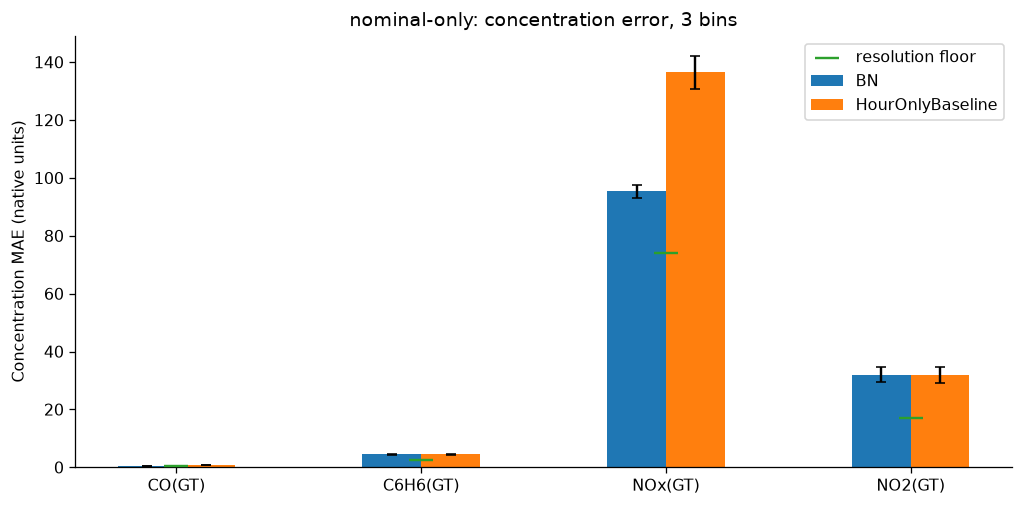

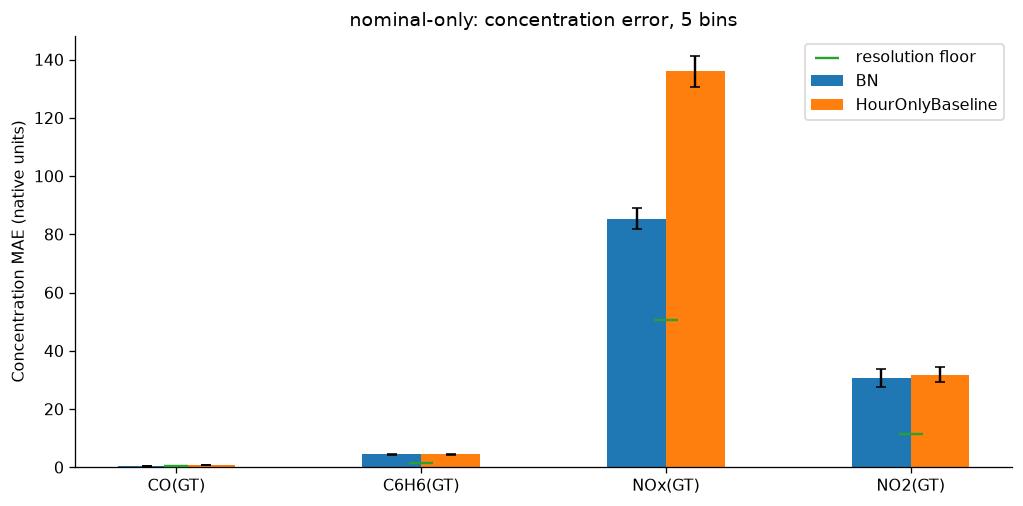

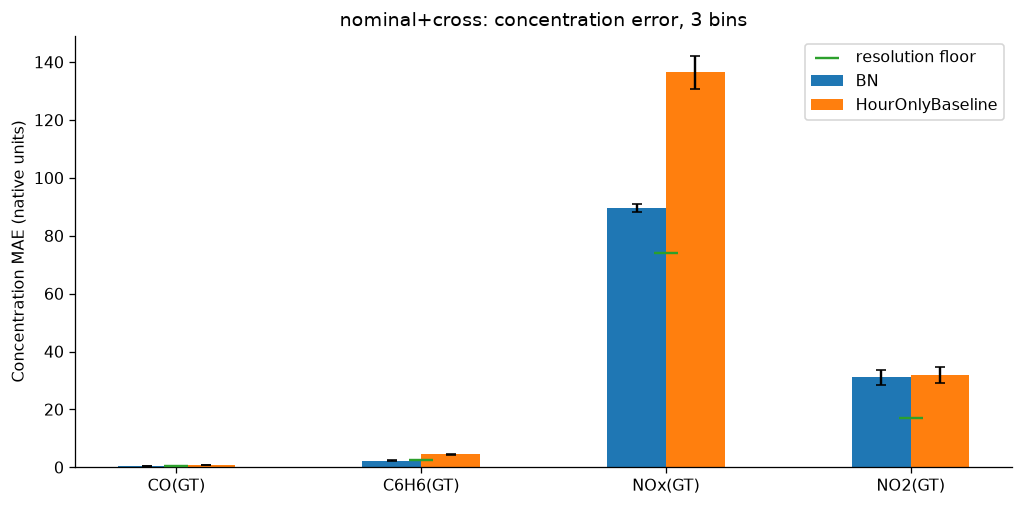

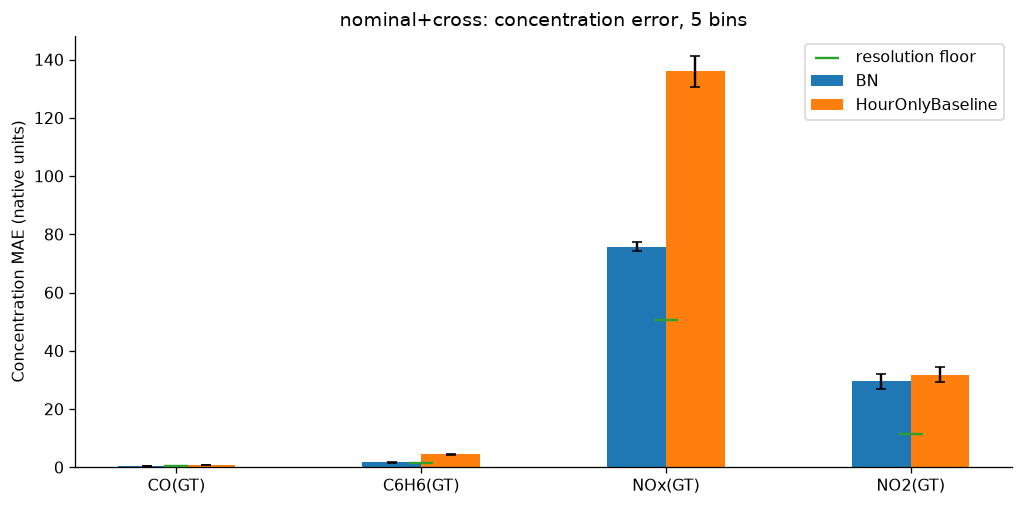

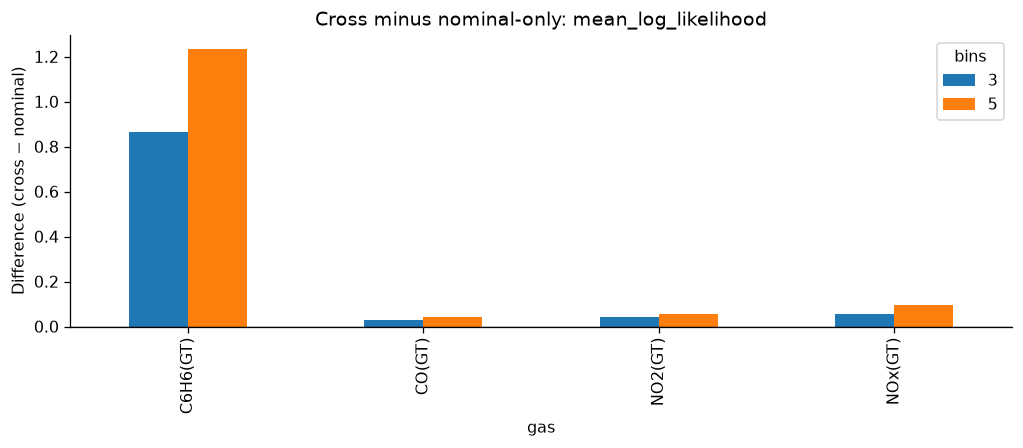

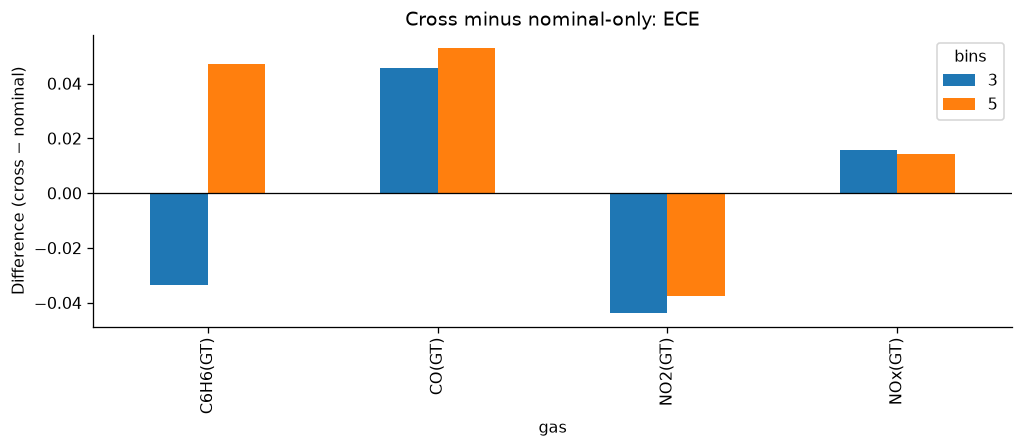

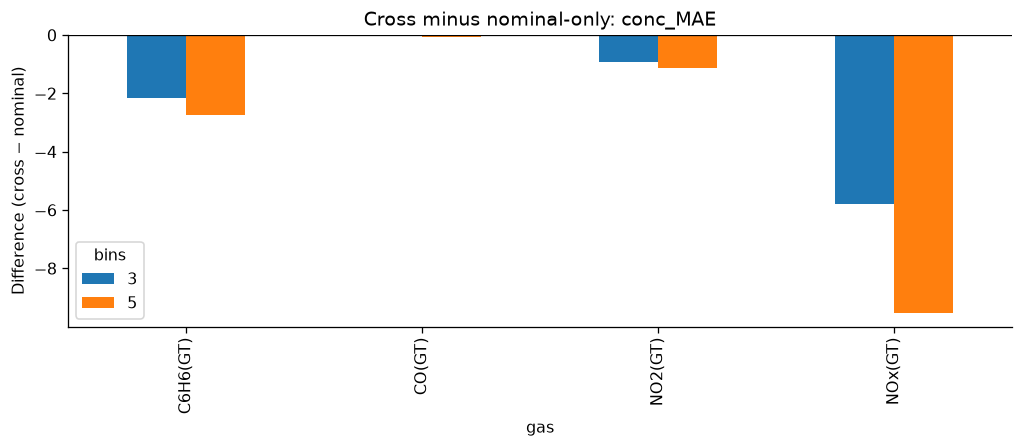

In [34]:
metrics_grid.to_csv(GRID_PATH,index=False)
conc_summary.to_csv(RESULT_DIR/'phase2_concentration_summary.csv',index=False)
metric_summary.to_csv(RESULT_DIR/'phase2_metric_summary.csv',index=False)
edge_deltas.to_csv(RESULT_DIR/'nominal_vs_cross_paired_deltas.csv',index=False)
selection_grid.to_csv(RESULT_DIR/'selection_scores_by_seed.csv',index=False)

# MAE by gas/model, one panel per bin count and edge set.
for edge_name in ['nominal-only','nominal+cross']:
    for n_bins in BIN_COUNTS:
        sub=conc_summary[(conc_summary.edges==edge_name)&(conc_summary.bins==n_bins)]
        fig,ax=plt.subplots(figsize=(9,4.5))
        gases=[str(g) for g in GASES]; x=np.arange(len(gases)); width=.24
        for j,model_name in enumerate(['BN','HourOnlyBaseline']):
            q=sub[sub.model==model_name].set_index('gas').reindex(gases)
            ax.bar(x+(j-.5)*width,q.MAE_mean,width,yerr=q.MAE_std,capsize=3,label=model_name)
        floor=sub[sub.model=='BN'].set_index('gas').reindex(gases)
        ax.scatter(x,floor.floor_MAE_mean,marker='_',s=220,label='resolution floor',zorder=4)
        ax.set_xticks(x,gases); ax.set_ylabel('Concentration MAE (native units)')
        ax.set_title(f'{edge_name}: concentration error, {n_bins} bins')
        ax.legend(); fig.tight_layout()
        fig.savefig(FIG_DIR/f'mae_{edge_name.replace("+","_")}_{n_bins}bins.png',bbox_inches='tight')
        plt.show()

# Cross-edge deltas for calibration and log-likelihood.
for metric in ['mean_log_likelihood','ECE','conc_MAE']:
    sub=edge_deltas.groupby(['bins','gas'])[f'{metric}_cross_minus_nominal'].mean().unstack('bins')
    ax=sub.plot(kind='bar',figsize=(9,4),title=f'Cross minus nominal-only: {metric}')
    ax.axhline(0,color='black',lw=.8); ax.set_ylabel('Difference (cross − nominal)')
    plt.tight_layout(); plt.savefig(FIG_DIR/f'cross_delta_{metric}.png',bbox_inches='tight'); plt.show()

**19. Export selected validation estimates and decision proposal**

In [35]:
selected_estimates=pd.DataFrame(index=chosen_models['val'].index)
for gas in GASES:
    selected_estimates[str(gas)] = chosen_preds['BN'][gas]['estimate']
selected_estimates.to_csv(RESULT_DIR/'phase2_validation_estimates_selected.csv',index_label='datetime')

WRITE_DECISION=False  # Change to True only after team review.
edge_text='nominal-only' if CHOSEN_EDGES=='nominal-only' else 'nominal + cross'
decision_line=(
    f'- 2026-11-10 — Phase 2 multi-gas recovery evaluation — selected {edge_text} edges '
    f'and {CHOSEN_BINS} bins (representative seed {CHOSEN_SEED}) using validation '
    f'normalized concentration gap above the resolution floor. NMHC remains excluded '
    f'from the primary graph due to approximately 90% missing reference readings; '
    f'EM/complete-case, sensor ablation, conditional gas dependence, and chronological '
    f'drift diagnostics are reported in notebooks/experiments/phase2_eval.ipynb.'
)
print(decision_line)
if WRITE_DECISION:
    with Path('docs/decisions.md').open('a',encoding='utf-8') as f:
        f.write('\n'+decision_line+'\n')

- 2026-11-10 — Phase 2 multi-gas recovery evaluation — selected nominal + cross edges and 3 bins (representative seed 1) using validation normalized concentration gap above the resolution floor. NMHC remains excluded from the primary graph due to approximately 90% missing reference readings; EM/complete-case, sensor ablation, conditional gas dependence, and chronological drift diagnostics are reported in notebooks/experiments/phase2_eval.ipynb.


**Assumptions, interpretation, and limitations checklist**

**A1: Gases are independent given hour**

The conditional mutual information analysis shows that several gas pairs retain statistical dependence after conditioning on hour. The strongest dependencies ocuur between CO and C6H6 (0.5457 bits) and NOx and NO2 (0.4147 bits). This suggest taht the gases are not fulling independent give hour alone. Therefore, A1 is a simplifying modeling assumption that is not fully supported by the observed data. The network may fail to capture some relationships between gases, potentially limiting join inference.

**A2: Sensors are independent given their gas parents and weather**

The partial Spearman correlation analysis identifies residual dependencies between several sensor pairs after controlling for gas concentrations, weather, and hour. The strongest correlations are between S1 and S5 (0.4701), S3 and S4 (0.3738), and S1 and S3 (-0.2889). These results suggest that the current graph does not capture all dependencies between sensors. Therefore, A2 is not fully supported by the data, although the conditional-independence assumption remains a useful simplification for limiting network complexity.

**A3: Missingness is ignorable given observed values (MAR)**

Missingness varies substantially across variables. CO, NOx, and NO2 have approximately 18% missing reference observations, while C6H6 has no missing observations after required-input filtering. NMHC has approximately 90% missing reference observations and is therefore excluded from the primary network. EM is used to estimate CPTs from incomplete observations rather than requiring complete-case data. However, the missingness analysis does not establish that the MAR assumption holds. MAR remains an assumption required by the missing-data treatment rather than a verified property of the dataset.

**A4: Hours are independent given the CPTs**

The network does not explicty model temporal dependencies between consecutive observations. THe chronological validation experiment shows that the Bayesian netowrk retains predictive ability for three of the four gases relative to the hour-only baseline. but its performances changes compared with the main validation results. For NO2, the chronological Bayesian network has slight higher MAE than the hour-only baseline. These results sugges that temporal distribution shifts can affect model performance. Since the model does not represent temporal transitions, A4 remains a simplifying assumption.

**Overall Interpretation**

The validation experiments selected the nominal-plus-cross-senstivity network with three bins because it achieved the smallest normalized concentration error gap above the discretization resolution floor. Adding cross-senstivity edges imrpoved concentration MAE across all four modeled gases compared with the nominal-only structure.

On the held-out test set, the selected Bayesian network achieved lower concentration MAE than the hour-only baseline for all four gases. The largest improvements were observed for C6H6, CO, and Nox, while NO2 showed a smaller improvement.

The sensor ablation experiment also demonstrated that individual sensors contribute differently to gas estimation. S2 was particulary important to C6H6, while S3 contributed substantially to NOx recovery.

Overall, the results support the usefulness of teh selected Bayesian network for multi-gas concentration recovery. However, the conditional independence diagnostics reveal residual dependencies between both gases and sensors. The model should therefore be interpreted as a useful approximation rather than a complete representation of the underlying air-quality relationships.

**Limitations**

The graph assumes gas variables are independent conditional on hour and sensors are independent conditonal on their gas parents and weather. Missingness is assumed MAR. Hours are treated as independent; no temporal state is carried between adjacent hours. C6H6 is nearly a transform of S2, so its recovery is not an independent sensor-based validation. NMHC is omitted because only a small early subset is observed. Calibration and CMI estimates are finite-sample diagnostics, not proof of model correctness. 